 ## Install and import libraries



In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn tensorflow joblib
!pip install -q kaggle

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully")

Libraries imported successfully


## Download the kaggle dataset

In [ ]:
csv_path = files[0]
df =pd.read_csv("/content/BankNote_Authentication.csv")
print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
['variance', 'skewness', 'curtosis', 'entropy', 'class']


In [ ]:
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully")

Saving BankNote_Authentication.csv to BankNote_Authentication.csv
Dataset uploaded successfully


## Load the dataset

In [ ]:
csv_files = glob.glob("/content/BankNote_Authentication.csv")

if not csv_files:
  raise FileNotFoundError("Please upload your kaggle CSV dataset.")

file_path = csv_files[0]

df = pd.read_csv(file_path)

# Handle CSV files without column headers
expected_columns = ["variance","skewness","curtosis","entropy","class"]

if not set(expected_columns).issubset(df.columns):
  df = pd.read_csv(file_path, header=None)
  if df.shape[1] == 5:
    df.columns = expected_columns
  else:
    raise ValueError("Dataset must contain 5 columns.")

print(df.head())
print("Dataset Shape:", df.shape)

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
Dataset Shape: (1372, 5)


## Explore the dataset

In [ ]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nClass Distribution:")
print(df["class"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
None

Statistical Summary:
          variance     skewness     curtosis      entropy        class
count  1372.000000  1372.000000  1372.000000  1372.000000  1372.000000
mean      0.433735     1.922353     1.397627    -1.191657     0.444606
std       2.842763     5.869047     4.310030     2.101013     0.497103
min      -7.042100   -13.773100    -5.286100    -8.548200     0.000000
25%      -1.773000    -1.708200    -1.574975    -2.413450     0.000000
50%       0.496180     2.319650     0.616630    -0.586650     0.000000
75%       2.821475     6.

## Visualize the dataset

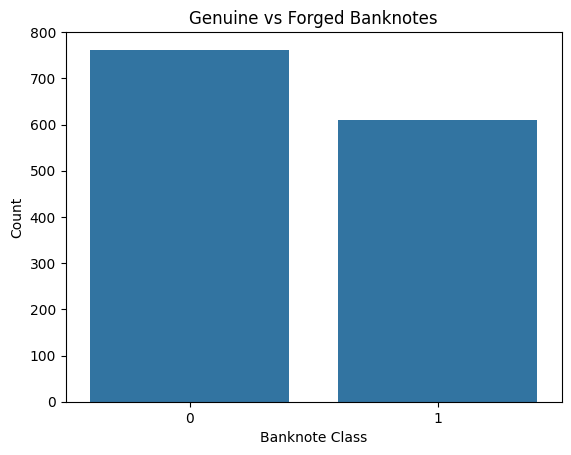

In [ ]:
sns.countplot(data=df, x="class")

plt.title("Genuine vs Forged Banknotes")
plt.xlabel("Banknote Class")
plt.ylabel("Count")
plt.show()

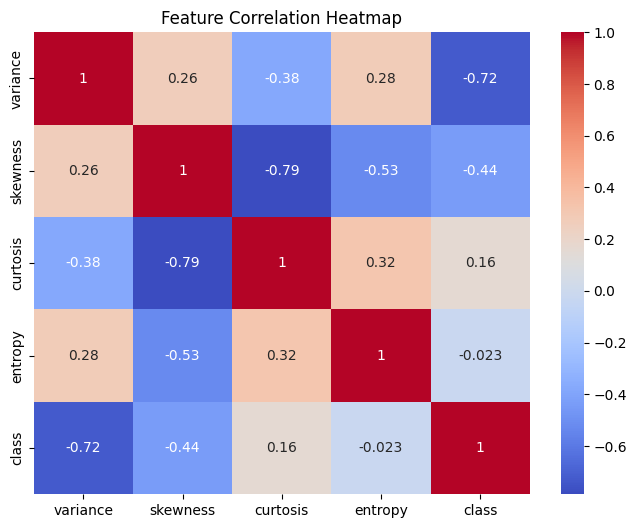

In [ ]:
# Feature correlation
plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

plt.title("Feature Correlation Heatmap")
plt.show()

## Preprocess the dataset

In [ ]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Handle missing values
df = df.dropna()

# Separate input and output
X = df[["variance", "skewness", "curtosis", "entropy"]]

y = df["class"].astype(int)

# Check class labels
print("Classes:", sorted(y.unique()))

if not set(y.unique()).issubset({0, 1}):
  raise ValueError("Target must contain only 0 and 1.")

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Classes: [np.int64(0), np.int64(1)]
Training records: 1078
Testing records: 270


## Implement SVM algorithm

In [ ]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")

svm_model.fit(X_train_scaled, y_train)

svm_predictions = svm_model.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, svm_predictions))

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_predictions, zero_division=0))

SVM Accuracy: 0.9962962962962963

SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       148
           1       0.99      1.00      1.00       122

    accuracy                           1.00       270
   macro avg       1.00      1.00      1.00       270
weighted avg       1.00      1.00      1.00       270



## Implement KNN algorithm

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5, metric="euclidean")

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, knn_predictions))

print("\nKNN Classification Report:")
print(classification_report(y_test, knn_predictions, zero_division=0))

KNN Accuracy: 1.0

KNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       148
           1       1.00      1.00      1.00       122

    accuracy                           1.00       270
   macro avg       1.00      1.00      1.00       270
weighted avg       1.00      1.00      1.00       270



## Implement ANN algorithm

In [ ]:
ann_model = Sequential([Dense(64, activation="relu", input_shape=(4,)), Dropout(0.2),
                        Dense(32, activation="relu"), Dropout(0.2),
                        Dense(16, activation="relu"),
                        Dense(1, activation="sigmoid")])
ann_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = ann_model.fit(X_train_scaled, y_train, epochs=100, batch_size=32, validation_split=0.2,
                        callbacks=[early_stop], verbose=1)

ann_probabilities = ann_model.predict(X_test_scaled).ravel()

ann_predictions = (ann_probabilities >= 0.5).astype(int)

print("ANN Accuracy:", accuracy_score(y_test, ann_predictions))

print("\nANN Classification Report:")
print(classification_report(y_test, ann_predictions, zero_division=0))

Epoch 1/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5870 - loss: 0.6511 - val_accuracy: 0.8704 - val_loss: 0.5590
Epoch 2/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8457 - loss: 0.5073 - val_accuracy: 0.9444 - val_loss: 0.4166
Epoch 3/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9223 - loss: 0.3552 - val_accuracy: 0.9676 - val_loss: 0.2543
Epoch 4/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9606 - loss: 0.2109 - val_accuracy: 0.9815 - val_loss: 0.1208
Epoch 5/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9768 - loss: 0.1131 - val_accuracy: 0.9954 - val_loss: 0.0536
Epoch 6/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9803 - loss: 0.0696 - val_accuracy: 0.9954 - val_loss: 0.0279
Epoch 7/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9884 - loss: 0.0506 - val_accuracy: 1.0000 - val_loss: 0.0164
Epoch 8/100
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9919 - loss: 0.0321 - val_accuracy: 1.0000 - 

## Compare all three algorithms

In [ ]:
models_predictions = {"SVM": svm_predictions,
                      "KNN": knn_predictions,
                      "ANN": ann_predictions}
results = []

for model_name, predictions in models_predictions.items():
    results.append({"Algorithm": model_name, "Accuracy": accuracy_score(y_test, predictions),
                    "Precision": precision_score(y_test, predictions,zero_division=0),
                    "Recall": recall_score(y_test, predictions, zero_division=0),
                    "F1 Score": f1_score(y_test, predictions, zero_division=0)})

results_df = pd.DataFrame(results)

print(results_df)

  Algorithm  Accuracy  Precision  Recall  F1 Score
0       SVM  0.996296    0.99187     1.0  0.995918
1       KNN  1.000000    1.00000     1.0  1.000000
2       ANN  1.000000    1.00000     1.0  1.000000


## Accuracy comparison graph

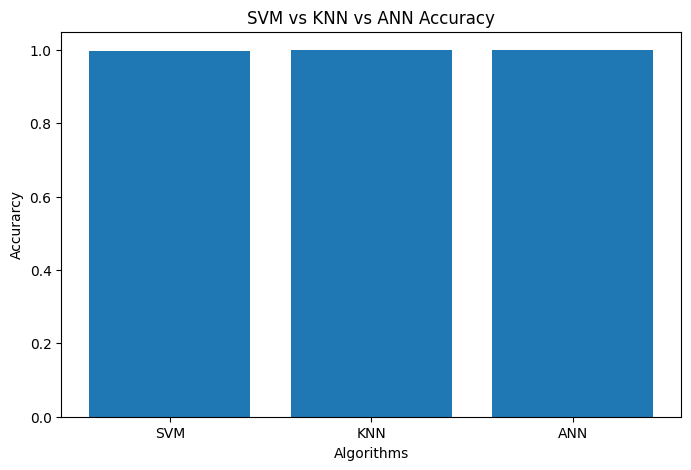

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Algorithm"], results_df["Accuracy"])

plt.title("SVM vs KNN vs ANN Accuracy")
plt.xlabel("Algorithms")
plt.ylabel("Accurarcy")

plt.ylim(0, 1.05)
plt.show()

## Confusion matrices

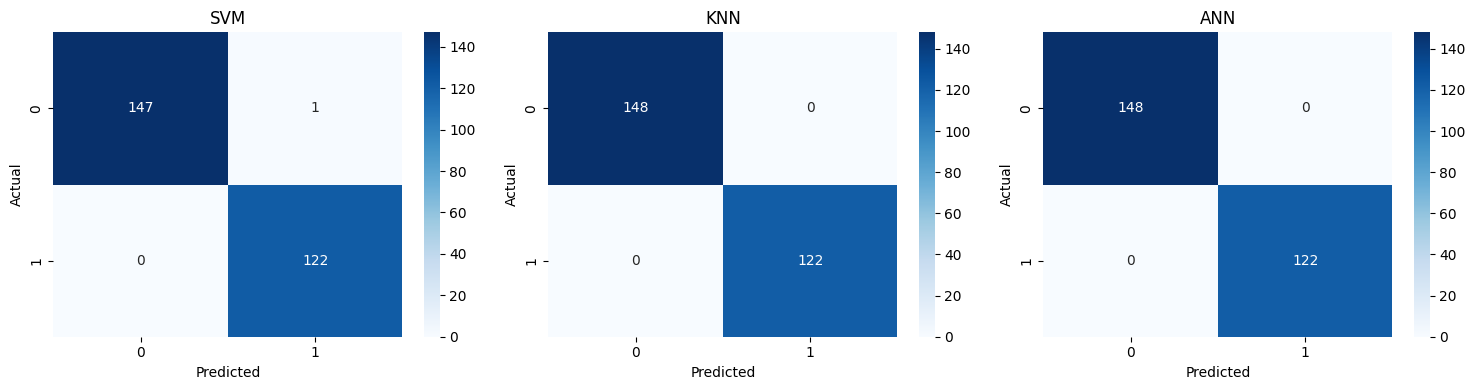

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models_predictions.items()):
  cm = confusion_matrix(y_test, predictions, labels=[0, 1])
  sns.heatmap(cm, annot=True, fmt="d",cmap="Blues",ax=ax)
  ax.set_title(name)
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## ANN training and validation accuracy


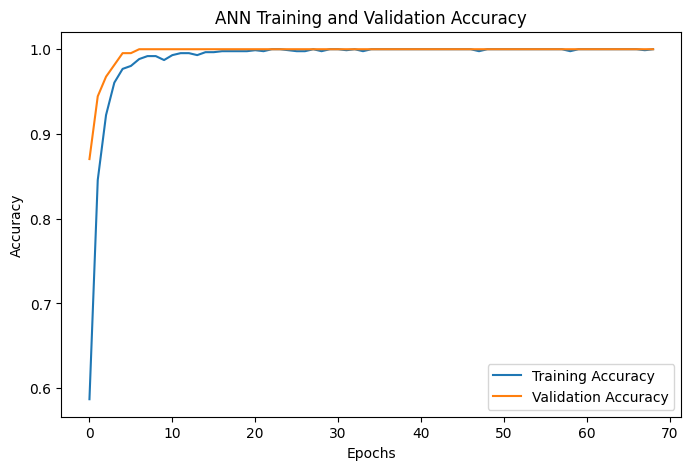

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("ANN Training and Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

## Predict a new banknote

In [ ]:
print("Enter Banknote Features")

variance = float(input("Enter Variance:"))

skewness = float(input("Enter Skewness:"))

curtosis = float(input("Enter Curtosis:"))

entropy = float(input("Enter Entropy:"))

new_note = pd.DataFrame([[variance, skewness, curtosis, entropy]],
                        columns=["variance", "skewness", "curtosis", "entropy"])

new_note_scaled = scaler.transform(new_note)

svm_result = svm_model.predict(new_note_scaled)[0]

knn_result = knn_model.predict(new_note_scaled)[0]

ann_result = (ann_model.predict(new_note_scaled, verbose=0)[0][0] >=0.5)

def get_label(prediction):
  return "Genuine Banknote" if prediction == 0 else "Forged Banknote"

print("\n----- PREDICTION RESULTS -----")

print("SVM:", get_label(svm_result))

print("KNN:", get_label(knn_result))

print("ANN:", get_label(int(ann_result)))

Enter Banknote Features
Enter Variance:0
Enter Skewness:1
Enter Curtosis:0
Enter Entropy:1

----- PREDICTION RESULTS -----
SVM: Forged Banknote
KNN: Forged Banknote
ANN: Forged Banknote


## Save the trained models

In [ ]:
# Save SVM and KNN
joblib.dump(svm_model, "svm_model.pkl")
joblib.dump(knn_model, "knn_model.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

# Save ANN
ann_model.save("ann_model.keras")

# Save comparison results
results_df.to_csv("model_comparison.csv", index=False)

print("ALL model saved successfully!")

ALL model saved successfully!
